# 11 高级别胶质瘤治疗后鉴别：基础临床模型

用户已批准改题及本步基础模型。问题是残余/复发肿瘤与治疗相关改变的探索性鉴别，使用UCSD-PTGBM公开资料；原OpenBTAI脑转移瘤未来RN风险问题仍暂停，两队列不合并。

先阅读固定方案`reports/ucsd_clinical_baseline_protocol.md`。只用年龄和性别，固定5折患者分组、种子20261029、C=1的Logistic回归，无调参。标签1为官方完整分组补集推导的肿瘤，标签0来自51条negative-case清单，不代表逐例病理证实或未来RN阴性。

In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
from IPython.display import display, Image
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
from rn_public.ucsd_clinical_baseline import make_cohort, run, FEATURES
cohort=make_cohort(ROOT)
assert len(cohort)==243 and cohort.patient_id.nunique()==178
assert cohort[FEATURES].notna().all().all()
print(cohort.groupby('tumor_label').agg(timepoints=('ID','size'),patients=('patient_id','nunique')))
display(cohort[cohort.diagnosis_text_anomaly.eq(1)][['ID','primary_diagnosis_raw','age_years','sex_at_birth_raw']])

             timepoints  patients
tumor_label                      
0                    51        39
1                   192       150


,ID,primary_diagnosis_raw,age_years,sex_at_birth_raw
66,UCSD-PTGBM-0043_01,"Astrocytoma, IDH-Mutant, Grade 5",45,Female


## 纳入与来源异常

保留全部243个时间点。源集合为高级别胶质瘤，包含少量非GBM诊断；一条Grade 5文本原样保留并标记，未作为预测变量。年龄和性别完整。11名患者在不同扫描中跨类，所有扫描留在同一验证折。原始亚型明细与官网介绍的计数差异仍保留，未补造RN。

In [2]:
assert cohort.groupby('patient_id').tumor_label.nunique().gt(1).sum()==11
assert set(FEATURES)=={'age_years','sex_male'}
summary=run(ROOT)
print('OOF results:',json.dumps(summary['logistic_oof'],indent=2))
print('Training-fold prevalence comparator:',json.dumps(summary['prevalence_only_oof'],indent=2))
print('Patient-cluster 95% intervals:',json.dumps(summary['patient_cluster_bootstrap_95ci'],indent=2))

OOF results: {
  "roc_auc": 0.5754697712418301,
  "ap_tumor": 0.8334609207416787,
  "ap_treatment_change": 0.2761602614946638,
  "brier": 0.16490878057028302,
  "sensitivity_tumor": 0.984375,
  "specificity_treatment_change": 0.0,
  "balanced_accuracy": 0.4921875,
  "accuracy": 0.7777777777777778,
  "tn": 0,
  "fp": 51,
  "fn": 3,
  "tp": 189
}
Training-fold prevalence comparator: {
  "roc_auc": 0.48805147058823517,
  "ap_tumor": 0.7857120283666463,
  "ap_treatment_change": 0.20576880363956707,
  "brier": 0.16586540631878444,
  "sensitivity_tumor": 1.0,
  "specificity_treatment_change": 0.0,
  "balanced_accuracy": 0.5,
  "accuracy": 0.7901234567901234,
  "tn": 0,
  "fp": 51,
  "fn": 0,
  "tp": 192
}
Patient-cluster 95% intervals: {
  "roc_auc": {
    "lower": 0.4671243084191006,
    "upper": 0.6806964275294666
  },
  "ap_tumor": {
    "lower": 0.7596248317349655,
    "upper": 0.9026836514298524
  },
  "ap_treatment_change": {
    "lower": 0.1830164929728619,
    "upper": 0.443978061162

## 患者分组和折内预处理验证

下面独立核对每折患者不重叠、每个时间点恰有一个OOF概率，以及年龄缩放来自该训练折。对照概率也只来自该训练折，不能使用完整队列的结局比例。

In [3]:
d=pd.read_csv(ROOT/'data/processed/ucsd_clinical_oof_predictions.csv')
folds=json.loads((ROOT/'reports/ucsd_clinical_baseline/fold_audit.json').read_text())
assert d.ID.nunique()==len(d)==243
assert d.groupby('patient_id').validation_fold.nunique().eq(1).all()
for f in folds:
    train=d[d.validation_fold.ne(f['fold'])]; test=d[d.validation_fold.eq(f['fold'])]
    assert set(train.patient_id).isdisjoint(test.patient_id)
    assert set(test.patient_id)==set(f['test_patients'])
    assert np.isclose(train.age_years.mean(),f['train_age_mean'])
    assert np.isclose(train.age_years.std(ddof=0),f['train_age_sd'])
    assert np.allclose(test.oof_prevalence_only_probability,train.tumor_label.mean())
display(pd.read_csv(ROOT/'reports/ucsd_clinical_baseline/fold_metrics.csv'))

,fold,n_train_patients,n_test_patients,n_train_timepoints,n_test_timepoints,test_tumor,test_treatment_change,train_prevalence,train_age_mean,train_age_sd,roc_auc,brier
0,1,145,33,195,48,38,10,0.789744,54.435897,14.022317,0.619737,0.161879
1,2,143,35,195,48,38,10,0.789744,55.882051,12.411799,0.646053,0.157945
2,3,141,37,195,48,38,10,0.789744,56.810256,13.459146,0.503947,0.178780
3,4,143,35,194,49,38,11,0.793814,55.221649,13.748752,0.583732,0.170487
4,5,140,38,193,50,40,10,0.787565,55.217617,14.389630,0.618750,0.155719


## 结果可视化

ROC、肿瘤类PR曲线和5个分位区间的描述性校准图均基于OOF概率。肿瘤类占比约79%，其AP必须与这一比例同时解释。0.5阈值预先固定，未优化。患者整簇bootstrap 2000次，固定OOF概率；区间不涵盖重新训练和重划折的全部变异。

In [4]:
display(Image(filename=str(ROOT/'outputs/ucsd-clinical-baseline-20261029/clinical_baseline_validation.png')))
display(pd.read_csv(ROOT/'reports/ucsd_clinical_baseline/calibration_bins.csv'))
assert summary['external_validation'] is False and summary['model_selection_performed'] is False

## 最终参数及解释边界

全队列拟合仅保存可复建系数，不用训练集指标替代验证。年龄和性别模型信号即使很弱也如实保留，不通过换种子、阈值或试很多模型来追求高AUC。模型局限包括单中心回顾性样本、推导标签、混合组织学和重复扫描。结果不能表述为外部验证或临床可用模型。

本步没有加入MRI。下一阶段建议先审核新队列MRI获取途径、代表性样本和独立于标签定义的ROI方案；须用户再次批准后执行。

Approved clinical baseline finished. Next stage awaits user approval.


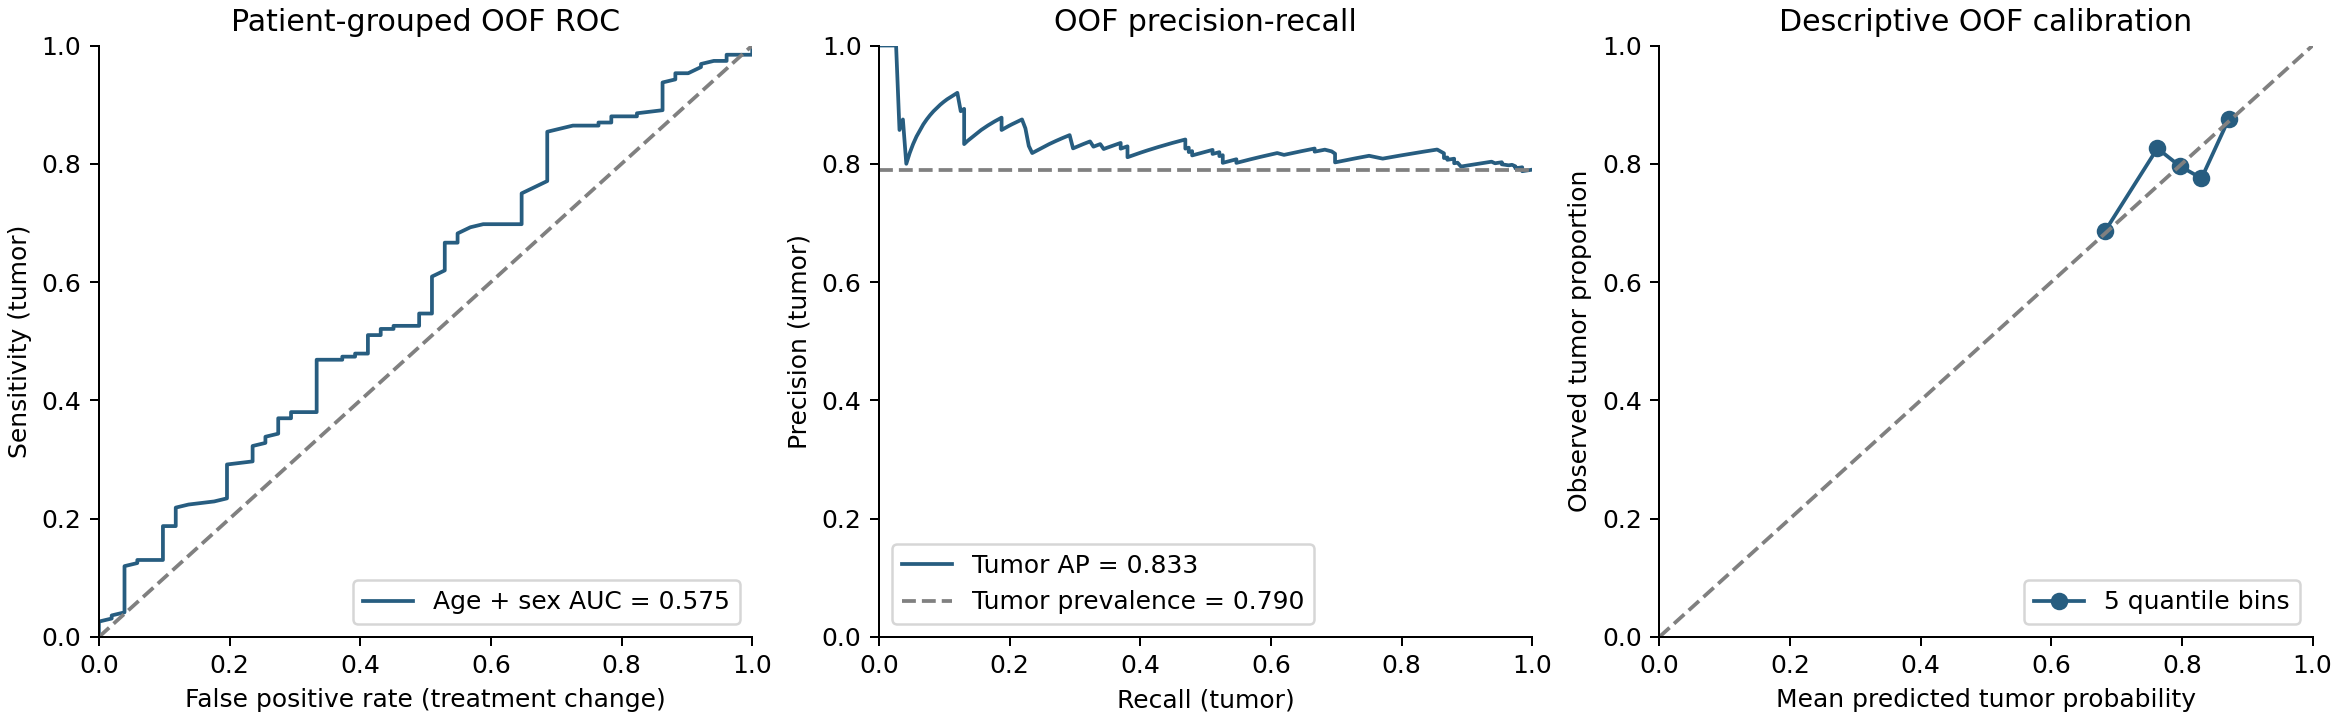

,mean_predicted_tumor_probability,observed_tumor_proportion
0,0.682277,0.686275
1,0.762389,0.826087
2,0.796982,0.795918
3,0.829913,0.775510
4,0.871405,0.875000


features                                                              [age_years, sex_male]
age_mean                                                                          55.514403
age_sd                                                                            13.644321
intercept                                                                           1.12551
coefficients_standardized_age_and_male             [0.4065759957010867, 0.3610974310143221]
age_odds_ratio_per_10_years                                                        1.347137
male_vs_female_odds_ratio                                                          1.434903
note                                      Full-cohort descriptive fit, not OOF performan...
dtype: object

In [5]:
display(pd.Series(summary['final_fit_parameters'],dtype=object))
assert summary['original_OpenBTAI_model_ready'] is False
assert summary['mri_features_used'] is False
assert summary['next_step_requires_user_approval'] is True
assert summary['protocol_sha256']==hashlib.sha256((ROOT/'reports/ucsd_clinical_baseline_protocol.md').read_bytes()).hexdigest()
print('Approved clinical baseline finished. Next stage awaits user approval.')